In [1]:
%load_ext autoreload
%autoreload 2
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [2]:
import sys
sys.path.append("../..")

In [3]:
from rom_tools.rom_manager import RomManager

In [4]:
rom_m = RomManager("../../../roms/sm_guinea_pig.smc", "../../../roms/sm_newlevel.smc")

In [5]:
objnames = rom_m.parse()

In [6]:
level_array = objnames["room_header_0x7acb3"].state_chooser.default.level_data.level_array.layer1

In [7]:
from world_rando.room_perception.isovision import *

In [8]:
is_air = mk_is_air(level_array)

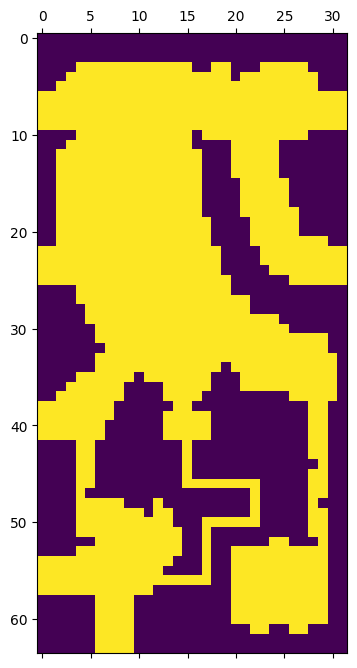

In [9]:
matshow(is_air.T)

In [12]:
from world_rando.room_perception.geometry import *
from world_rando.room_perception.perceptual_flux import *

In [13]:
def line_direction(segment):
    vector = segment[1] - segment[0]
    size = segment[0].euclidean(segment[1])
    return vector.scale(1/size)

In [39]:
def toward(point, segment):
    """Returns a unit vector pointing from point towards segment iff point is colinear with segment"""
    a, b = segment
    if point != a:
        return 


# Return a line segment that represents a line that bisects the lines defined by seg_a, seg_b
def bisect_line(segment_a, segment_b):
    print(segment_a, segment_b)
    i = line_intersect(segment_a, segment_b)
    if i is None:
        # If the lines are parallel, then the direction of the line is the same as both lines
        # The origin is between them.
        # The average of any two points on parallel segments will be halfway between them
        p = (segment_a[0] + segment_b[0]).scale(1/2)
        d = line_direction(segment_a)
        return (p, p + d)
    else:
        p, t, same = i
        # WLOG use the first point to determine the direction
        if p != segment_a[0]:
            toward_a =
        toward_a = line_direction((p, segment_a[0]))
        toward_b = line_direction((p, segment_b[0]))
        # The sum of the directions bisects the angle
        return (p, p + toward_a + toward_b)

def line_intersect_segment(line, segment):
    i = line_intersect(line, segment)
    if i is None:
        return None
    else:
        p, t, same = i
        assert not same
        # Use strict because it needs to strictly intersect in order for the line to be Voronoi-relevant
        if t[1] > 0 or t[1] < 1:
            return p
        else:
            return None

In [24]:
class VoronoiRegion(object):

    def __init__(self, anchor, segments):
        self.anchor = anchor
        self.segments = segments
        # Check that the segments define a region
        assert self.anchor[1] == self.segments[0][0]
        assert self.anchor[0] == self.segments[-1][1]
        for i in range(len(self.segments) - 1):
            seg_a = self.segments[i]
            seg_b = self.segments[i+1]
            assert seg_a[1] == seg_b[0]

    def add_line(self, line):
        assert line_intersect_segment(line, self.anchor) is None
        i1 = None
        i2 = None
        i1_index = None
        i2_index = None
        for i,seg in enumerate(self.segments):
            p = line_intersect_segment(line, seg)
            if p is not None:
                if i1 is None:
                    i1 = p
                    i1_index = i
                else:
                    if i2 is None:
                        i2 = p
                        i2_index = i
                    else:
                        assert False, "Line cannot intersect a convex shape more than two times!"
        # There should be exactly two or zero intersection points. If there are zero, no changes are neeeded
        # If there are two intersection points, then the line cuts the two affected segments partway, and removes the intervening segments entirely
        if i1 is not None:
            assert i2 is not None, "Line cannot intersect one point!"
            new_segment = (i1, i2)
            i1_seg = self.segments[i1_index]
            i2_seg = self.segments[i2_index]
            new_i1 = (i1_seg[0], i1)
            new_i2 = (i2, i2_seg[1])
            # 
            self.segments = self.segments[0: i1_index] + [new_i1, new_segment, new_i2] + self.segments[i2_index+1:]

In [31]:
surfaces, subsegs = mk_lines(is_air)

In [32]:
boundaries = mk_boundary_surfaces(is_air)

In [37]:
def mk_bisects(surfaces):
    bisects = defaultdict(dict)
    for s_i, s_j in combinations(surfaces, 2):
        bisect = bisect_line(s_i, s_j)
        bisects[s_i][s_j] = bisect
    return bisects

def mk_regions(surfaces):
    pass

In [41]:
#TODO: this idea is fundamentally wrong: the delaunay graph for line segments can have parabolically-curved segments
#mk_bisects(surfaces)